# A2-1 기능 요구사항별 실행과 검증

과제 원문 **4. 기능 요구 사항**(PDF 3~4쪽)의 30개 항목을 나열된 순서대로 따라간다. `1-1`은 1번 주제의 첫 번째 항목이다. 각 항목에서 무엇을 확인하는지 읽고 바로 아래의 계산값, 그림 또는 수식으로 결과를 확인한다.

`A2_1` 루트나 `notebooks/`에서 이 파일을 열고, 프로젝트의 Python 환경을 커널로 선택한 뒤 처음부터 실행한다. 저장된 그림과 수치 출력은 실행 전에도 볼 수 있다. 수치 기준은 `assert`로 확인하며 그림은 셀 안에 표시한다.

[과제 원문 전사본](<../../AI가 어떻게 학습하는지 수학으로 직접 풀어보기.md#4-기능-요구-사항>) · [프로젝트 실행 방법](../README.md)

## 과제 목표와 연결되는 기능 요구사항

아래는 과제 요구서 3절의 목표다. 관련 범위의 마지막 실행 결과 바로 뒤에서, 방금 본 수식과 출력으로 해당 목표를 정리한다.

| 과제 목표 원문 | 관련 기능 요구사항 |
| --- | --- |
| 행렬 곱셈이 공간을 어떻게 변형시키는지, 행렬식이 면적 변화율과 어떻게 연결되는지 설명할 수 있다 | 1-1~1-4 |
| 고유값과 고유벡터가 선형 변환에서 어떤 의미를 가지는지, SVD가 데이터 압축에 어떻게 활용되는지 이해한다 | 1-5~1-7 |
| 연쇄 법칙을 사용하여 2층 신경망의 역전파 수식을 유도하고, 각 가중치에 대한 기울기를 손계산할 수 있다 | 3-1~3-7 (2-1~2-4는 미분·그래디언트의 기초) |
| MSE와 Cross-Entropy 손실 함수의 확률적 의미를 구분하고, MLE와의 연결을 수식으로 설명할 수 있다 | 5-1~5-5 |
| Learning Rate와 Momentum이 경사하강법 수렴에 미치는 영향을 실험 결과와 함께 설명할 수 있다 | 4-1~4-7 (2-2~2-4는 등고선과 이동 방향의 기초) |

In [1]:
from functools import partial
from io import BytesIO
from pathlib import Path
import sys

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.quiver import Quiver
from matplotlib.transforms import Bbox
import numpy as np
from IPython.display import Image, display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
assert (root / "src/linear_algebra.py").is_file(), "A2_1 또는 notebooks/에서 실행하세요."
sys.path.insert(0, str(root))
from src import calculus as calc, linear_algebra as la, optimizer as opt

np.random.seed(42)
np.set_printoptions(precision=8, suppress=False)

def show_figure(figure, bounds="tight"):
    '''그림을 PNG로 변환해 현재 셀에 표시한다.'''
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=110, bbox_inches=bounds)
        display(Image(data=buffer.getvalue(), format="png"))
    plt.close(figure)

## 1. 선형대수: 행렬 변환과 분해

### 1-1. 단위 원에 회전 행렬 적용

**과제 요구서 원문**

> 단위 원에 회전 행렬 R(θ)를 적용하고 변환 전후를 하나의 Figure에 겹쳐 출력한다

원 위의 점 $p=(\cos t,\sin t)$마다 $R(\theta)p$를 계산한다. $\theta=45^\circ$일 때 원의 외곽선은 그대로이므로, 파란 빈 점 $(1,0)$과 붉은 점 $(\sqrt{2}/2,\sqrt{2}/2)$을 비교하면 회전이 보인다. `plot_transformations()`가 만든 세 패널을 하나씩 펼쳐 본다.

$$R(\theta)=\begin{bmatrix}\cos\theta&-\sin\theta\\\sin\theta&\cos\theta\end{bmatrix}.$$

**행렬의 열을 보면 공간 전체의 변환을 알 수 있다.** $e_1=(1,0)$, $e_2=(0,1)$를 좌표축의 기본 방향이라고 하자. 점 $p=(x,y)=xe_1+ye_2$를 변환하면 $Ap=x(Ae_1)+y(Ae_2)$이다. $Ae_1$과 $Ae_2$는 $A$의 첫째 열과 둘째 열이므로, 두 방향의 이동만 알면 모든 점의 새 위치를 계산할 수 있다. 코드에서 점을 행으로 저장하므로 `points @ A.T`로 같은 계산을 한다.

회전 행렬의 두 열은 각각 $(\cos\theta,\sin\theta)$와 $(-\sin\theta,\cos\theta)$다. 변환된 두 축은 여전히 길이 1이고 서로 직교한다. 실제로 $(\cos t,\sin t)$를 대입하면 삼각함수 덧셈 공식에 의해 $(\cos(t+\theta),\sin(t+\theta))$가 된다. 모든 점의 방향이 $45^\circ$씩 바뀌고 원점까지의 거리는 유지된다. 그림에서 원이 겹치는 이유와 기준점의 이동을 함께 확인할 수 있다.

기준점 (1, 0) → [0.70710678 0.70710678], 원점까지의 거리 1


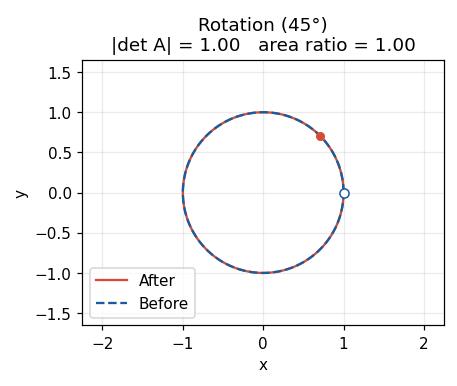

In [2]:
transform_figure, area_stats = la.plot_transformations()
transform_figure.canvas.draw()
transform_figure.set_layout_engine(None)

def show_transform(index):
    '''기존 행렬 변환 Figure에서 해당 패널을 확대해 표시한다.'''
    panel = transform_figure.axes[index]
    for axes in transform_figure.axes:
        axes.set_visible(axes is panel)
    panel.legend(loc="lower left")
    transform_figure.canvas.draw()
    box = panel.get_tightbbox(transform_figure.canvas.get_renderer())
    inches = box.transformed(transform_figure.dpi_scale_trans.inverted())
    padded = Bbox.from_extents(inches.x0 - 0.12, inches.y0 - 0.12,
                              inches.x1 + 0.12, inches.y1 + 0.12)
    show_figure(transform_figure, padded)

theta = np.pi / 4
rotated = np.array([np.cos(theta), np.sin(theta)])
np.testing.assert_allclose(np.linalg.norm(rotated), 1)
print(f"기준점 (1, 0) → {rotated}, 원점까지의 거리 1")
show_transform(0)

### 1-2. 단위 원에 스케일링 행렬 적용

**과제 요구서 원문**

> 단위 원에 스케일링 행렬 S(2, 0.5)를 적용하고 타원 형태의 결과를 출력한다

$S=\operatorname{diag}(2,0.5)$를 곱하면 $(x,y)$가 $(2x,0.5y)$로 이동한다. 그림의 파란 점선은 변환 전 단위 원, 붉은 실선은 변환 후 타원이다. 두 반지름이 각각 2와 0.5가 되는지 확인한다.

변환 후 좌표를 $(u,v)=(2x,0.5y)$라고 두면 $x=u/2$, $y=v/0.5$이다. 원래 식 $x^2+y^2=1$에 대입하면 $(u/2)^2+(v/0.5)^2=1$이 된다. 바로 반지름이 가로 2, 세로 0.5인 타원의 식이다. 좌표축 방향은 유지되지만 가로로 늘고 세로로 줄기 때문에 원의 모양이 바뀐다. 그림에서 붉은 타원이 축과 만나는 위치가 코드가 출력한 두 양의 기준점이다.

가로 기준점 (1, 0) → [2. 0.]
세로 기준점 (0, 1) → [0.  0.5]


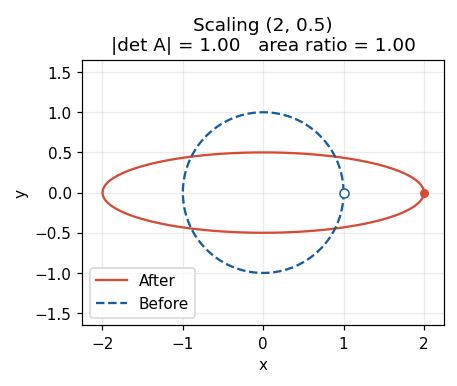

In [3]:
scaling = np.diag([2.0, 0.5])
print(f"가로 기준점 (1, 0) → {scaling @ [1, 0]}")
print(f"세로 기준점 (0, 1) → {scaling @ [0, 1]}")
show_transform(1)

### 1-3. 단위 원에 전단 행렬 적용

**과제 요구서 원문**

> 단위 원에 전단 행렬 Sh(k)를 적용하고 기울어진 형태의 결과를 출력한다

$Sh(k)=\begin{bmatrix}1&k\\0&1\end{bmatrix}$에 $k=1$을 대입하면 $(x,y)$는 $(x+y,y)$가 된다. $y>0$인 점은 오른쪽으로, $y<0$인 점은 왼쪽으로 이동해 도형이 기울어진다.

첫째 열이 $(1,0)$이므로 가로축 방향은 그대로이고, 둘째 열이 $(1,1)$이므로 세로축 방향은 대각선으로 바뀐다. 높이 $y$가 같은 점들은 모두 가로로 $ky$만큼 이동한다. 각 높이에서 원의 수평 단면 길이는 같고 단면의 위치만 달라지므로, 기울어진 도형의 면적은 원과 같다. 다음 항목에서 이 사실을 행렬식과 실제 면적 계산으로 확인한다.

(0, 1) → [1 1]; (0, -1) → [-1 -1]


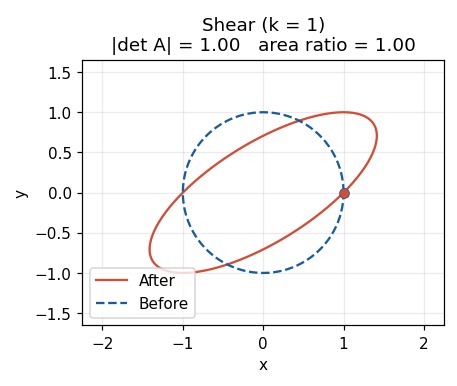

In [4]:
shear = np.array([[1, 1], [0, 1]])
print(f"(0, 1) → {shear @ [0, 1]}; (0, -1) → {shear @ [0, -1]}")
show_transform(2)

### 1-4. 행렬식과 실제 면적비 비교

**과제 요구서 원문**

> 행렬식 det(A)를 계산하고, 변환 후 도형의 면적 비율과 비교하여 오차가 1% 이내임을 확인한다

선형변환 $A$를 적용하면 면적은 $|\det A|$배가 된다. 구현은 원을 구성하는 100개 점과 변환된 점의 다각형 면적을 각각 신발끈 공식으로 구한다. 아래 상대 오차는 `|면적비 − |det A|| / |det A|`이며 통과 기준은 **1% 이하**다.

**왜 행렬식이 면적 배율인가?** $A=\begin{bmatrix}a&b\\c&d\end{bmatrix}$는 단위 정사각형의 두 변을 $(a,c)$와 $(b,d)$로 보낸다. 이 두 벡터가 만드는 평행사변형의 면적은 $|ad-bc|=|\det A|$다. 임의의 두 변을 열로 가진 행렬을 $B$라고 하면 변환 전후 면적은 각각 $|\det B|$와 $|\det(AB)|$다. $\det(AB)=\det A\,\det B$이므로 삼각형도 같은 배율을 가지며, 도형을 삼각형으로 나누어 합한 면적에도 이 배율이 적용된다. 부호는 방향의 보존 또는 반전을 나타내고, 면적에는 절댓값을 사용한다.

세 행렬에서 각각 $\cos^2\theta+\sin^2\theta=1$, $2\cdot0.5=1$, $1\cdot1-1\cdot0=1$이므로 예상 면적비는 모두 1이다. 코드는 점의 좌표만 사용해 각 다각형의 면적 $\tfrac12\left|\sum_i(x_i y_{i+1}-y_i x_{i+1})\right|$을 따로 계산한다. 아래에 출력된 비율과 행렬식이 맞는지 확인한다. 원본과 변환본에 동일한 100각형 근사를 사용하므로 비교 대상은 대응하는 두 다각형의 면적비다. 가장 큰 오차 약 $8.9\times10^{-16}$도 기준 $0.01$보다 작다.

In [5]:
for name, (det, ratio, error) in area_stats.items():
    assert error <= 0.01, name
    print(f"{name:18s} det={det:.6f}  면적비={ratio:.6f}  상대 오차={error:.3e}  [충족]")

Rotation (45°)     det=1.000000  면적비=1.000000  상대 오차=6.661e-16  [충족]
Scaling (2, 0.5)   det=1.000000  면적비=1.000000  상대 오차=0.000e+00  [충족]
Shear (k = 1)      det=1.000000  면적비=1.000000  상대 오차=8.882e-16  [충족]


### 과제 목표 1 정리 — 행렬 변환과 면적 변화율

**목표 원문**  
행렬 곱셈이 공간을 어떻게 변형시키는지, 행렬식이 면적 변화율과 어떻게 연결되는지 설명할 수 있다

점 $p=(x,y)$를 $Ap=x(Ae_1)+y(Ae_2)$로 쓸 수 있다. 행렬의 두 열 $Ae_1,Ae_2$가 기본 방향을 어디로 보내는지 알면 공간의 모든 점이 어떻게 움직이는지 설명할 수 있다. `1-1`의 회전은 각 점을 $45^\circ$씩 돌리므로 원의 외곽선이 겹친다. `1-2`의 스케일링은 $(x,y)$를 $(2x,0.5y)$로 보내 가로 반지름 2, 세로 반지름 0.5인 타원을 만든다. `1-3`의 전단은 높이 $y$를 유지하면서 높이마다 다른 양만큼 가로로 민다.

행렬의 두 열은 단위 정사각형을 평행사변형으로 보내고 그 넓이는 $|\det A|$다. 같은 배율이 도형 전체의 넓이에도 적용된다. 스케일링에서는 가로 2배와 세로 0.5배의 곱이 1이고, 회전과 전단에서도 $|\det A|=1$이다. 방금 본 출력에서 세 변환의 실제 면적비가 모두 1이며 최대 상대 오차가 약 $8.88\times10^{-16}$이다. 타원과 전단 그림에서 **모양이 달라져도 면적은 같을 수 있다**는 사실을 확인할 수 있다.

**스스로 설명하기** — 스케일링 그림을 보고 축마다 무엇이 바뀌었는지 말한 뒤, $2\cdot0.5=1$을 이용해 면적이 같은 이유를 설명한다.

### 1-5. Power Iteration으로 최대 고유쌍 계산

**과제 요구서 원문**

> Power Iteration 알고리즘을 구현하여 최대 고유값을 계산한다

$A=\begin{bmatrix}4&1\\1&3\end{bmatrix}$를 벡터에 반복해서 곱하고 매번 길이를 1로 맞춘다. 절댓값이 가장 큰 고유값에 대응하는 방향이 남으면 레일리 몫 $v^\top Av$로 $\lambda$를 구한다. 여기서는 두 고유값이 양수여서 절댓값 기준 지배 고유값이 최대 고유값이다. $\|Av-\lambda v\|_2\le10^{-9}$인지 확인한다.

**고유벡터의 의미.** 일반적인 방향의 벡터는 $A$를 곱하면 방향과 길이가 함께 바뀐다. $Av=\lambda v$를 만족하는 영이 아닌 $v$는 변환 후에도 같은 직선 위에 있다. $\lambda>0$이면 방향을 유지하고 $\lambda<0$이면 반대쪽을 향한다. 여기서는 $v\approx(0.85065,0.52573)$가 같은 방향에서 약 4.618배 길어진다. 예를 들어 $A(1,0)=(4,1)$이므로 좌표축의 방향 $(1,0)$은 고유벡터가 아니다.

**반복하면 왜 그 방향이 남는가?** 이 대칭행렬에는 서로 직교하는 단위 고유벡터 $v_1,v_2$가 있다. 시작 벡터를 $c_1v_1+c_2v_2$로 쓰면 $t$번 곱한 값은 $c_1\lambda_1^t v_1+c_2\lambda_2^t v_2$다. $|\lambda_1|>|\lambda_2|$이고 $c_1\ne0$이면, 첫째 성분 대비 둘째 성분의 크기는 반복할 때마다 $|\lambda_2/\lambda_1|$배가 되어 0에 가까워진다. 매번 정규화해 길이가 커지는 것을 제어하면서 방향만 추적한다. 단위벡터에서 $v^\top Av\approx\lambda v^\top v=\lambda$를 사용하고, 잔차를 재서 이 고유쌍 식에 얼마나 가까운지 확인한다.

In [6]:
matrix = np.array([[4.0, 1.0], [1.0, 3.0]])
eigenvalue, eigenvector, iterations = la.power_iteration(matrix)
residual = np.linalg.norm(matrix @ eigenvector - eigenvalue * eigenvector)
assert residual <= 1e-9
print(f"λ={eigenvalue:.10f}  v={eigenvector}  반복={iterations}회")
print(f"||Av - λv||₂ = {residual:.3e}  [충족]")

λ=4.6180339887  v=[0.85065081 0.52573111]  반복=33회
||Av - λv||₂ = 7.866e-10  [충족]


### 1-6. NumPy 고유값과 비교

**과제 요구서 원문**

> 직접 계산한 고유값과 np.linalg.eig 결과를 비교하여 오차가 5% 이내임을 확인한다

검증 기준으로 `np.linalg.eig(A)`의 최대 고유값을 사용한다. 상대 오차 $|\lambda-\lambda_{\rm ref}|/|\lambda_{\rm ref}|$가 **5% 이하**여야 한다. 고유벡터는 부호가 달라도 같은 방향을 나타내므로 내적의 절댓값도 확인한다.

잔차와 참조값은 서로 다른 질문에 답한다. 1-5의 잔차는 구한 두 값이 $Av=\lambda v$를 만족하는 정도다. 여러 고유쌍이 이 식을 만족할 수 있으므로 이 항목에서는 참조값 중 절댓값이 가장 큰 것을 골라 **목표 고유쌍**에 도달했는지 확인한다. 두 단위벡터의 내적 절댓값은 두 방향이 같은 직선 위에 있으면 1이다. 출력에서 고유값 상대 오차와 방향 일치를 함께 볼 수 있다.

In [7]:
reference_values, reference_vectors = np.linalg.eig(matrix)
dominant = np.argmax(np.abs(reference_values))
reference = reference_values[dominant]
error = abs(eigenvalue - reference) / abs(reference)
overlap = abs(eigenvector @ reference_vectors[:, dominant])
assert error <= 0.05 and 1 - overlap <= 1e-8
print(f"직접 계산={eigenvalue:.10f}  NumPy={reference:.10f}")
print(f"상대 오차={error:.3e}  고유벡터 내적의 절댓값={overlap:.10f}  [충족]")

직접 계산=4.6180339887  NumPy=4.6180339887
상대 오차=1.923e-16  고유벡터 내적의 절댓값=1.0000000000  [충족]


### 1-7. SVD로 복원한 이미지 비교

**과제 요구서 원문**

> SVD를 활용하여 이미지를 압축하고, k=10, 50, 100일 때 복원 결과를 하나의 Figure에 비교 출력한다

64×64 회색조 이미지를 $U\Sigma V^\top$로 분해하고, 상위 $k$개 성분으로 $U_k\Sigma_kV_k^\top$를 계산한다. 원본과 **요청값 10, 50, 100**의 복원을 한 Figure에서 비교한다. 이미지에 사용할 수 있는 성분은 최대 64개이므로 $k=100$ 요청은 64개 전체를 사용한다. 표의 저장량은 원본 픽셀 수 대비 인자 원소 수다.

**픽셀을 어떻게 줄여 저장하는가?** 이미지 행렬 $M$을 $M=\sum_{i=1}^{64}\sigma_i u_i v_i^\top$로 쓸 수 있다. 각 $u_i v_i^\top$는 열 방향 패턴과 행 방향 패턴으로 만든 랭크 1의 이미지다. $\sigma_1\ge\cdots\ge\sigma_{64}\ge0$는 각 패턴에 붙는 가중치다. 가중치가 큰 패턴부터 $k$개를 보관한 뒤 합치면 복원 이미지 $M_k$가 된다.

한 패턴에는 세로 벡터 64개, 가로 벡터 64개, 특이값 1개로 총 129개의 숫자가 필요하다. $k=10$이면 1,290개라서 원본 4,096개의 약 **31.5%**로 윤곽을 복원한다. 픽셀 차이의 상대 크기 $\|M-M_k\|_F/\|M\|_F$는 약 **17.96%**다. $k=50$이면 오차가 약 **0.63%**로 줄어들지만 6,450개를 보관해야 한다. $k=100$ 요청에서는 64개를 모두 써 거의 정확히 복원하나 원소 수가 더 커진다. 이 비교의 저장량은 같은 자료형을 가정한 원소 수다. 그림의 유사도와 원소 수를 함께 보며 얼마만큼 압축할지 판단한다.

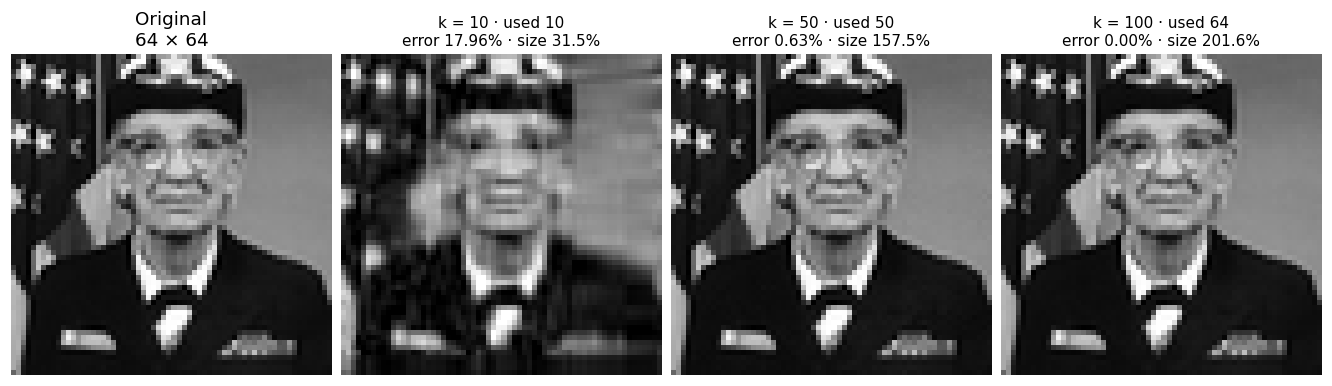

요청 k= 10  사용=10  상대 복원 오차=1.796e-01  저장량=31.5%
요청 k= 50  사용=50  상대 복원 오차=6.269e-03  저장량=157.5%
요청 k=100  사용=64  상대 복원 오차=1.507e-15  저장량=201.6%
요청한 세 경우를 한 Figure에 표시하고 성분 상한을 확인함  [조건 표시]


In [8]:
image = np.load(root / "data/grace_hopper_gray64.npy") / 255.0
assert image.shape == (64, 64)
svd_figure, svd_stats = la.plot_svd(image, ranks=(10, 50, 100))
used = [entry[0] for entry in svd_stats.values()]
errors = [entry[1] for entry in svd_stats.values()]
assert used == [10, 50, 64]
assert errors[0] >= errors[1] >= errors[2] and errors[2] <= 1e-12
show_figure(svd_figure)
for requested, (rank, error, size_ratio) in svd_stats.items():
    print(f"요청 k={requested:3d}  사용={rank:2d}  상대 복원 오차={error:.3e}  저장량={size_ratio:.1%}")
print("요청한 세 경우를 한 Figure에 표시하고 성분 상한을 확인함  [조건 표시]")

### 과제 목표 2 정리 — 고유벡터와 SVD 압축

**목표 원문**  
고유값과 고유벡터가 선형 변환에서 어떤 의미를 가지는지, SVD가 데이터 압축에 어떻게 활용되는지 이해한다

고유벡터는 $Av=\lambda v$를 만족하는 방향이다. 변환 후에도 같은 직선 위에 있고 길이는 $|\lambda|$배가 된다. 이 예제의 출력에서 $v\approx(0.85065,0.52573)$는 양의 고유값 $4.61803$에 대응하므로 방향을 유지하며 길이가 늘어난다. Power Iteration은 시작 벡터에 섞인 여러 방향 가운데 이 방향의 성분을 가장 빠르게 키운다. `1-6`의 NumPy 비교는 고유값과 방향이 모두 맞는지 확인한 것이다.

SVD는 회색조 이미지 하나를 특이값으로 가중한 여러 패턴의 합으로 표현한다. 큰 특이값부터 $k$개를 남기고 더하면 이미지를 근사 복원할 수 있다. 이 예제에서 한 패턴에 숫자 129개가 필요하다. $k=10$에서는 1,290개로 원본 4,096개의 31.5%만 쓰면서 윤곽을 복원했다. $k=50$에서는 오차가 약 0.63%로 줄지만 6,450개가 필요하다. $k=100$ 요청에서는 가능한 64개를 모두 사용해 원본을 거의 정확히 복원한다. 그림과 원소 수를 함께 비교하면 **복원 품질을 높이는 것과 저장량을 줄이는 것 사이의 관계**를 설명할 수 있다.

**스스로 설명하기** — $Av=\lambda v$에서 방향과 길이가 어떻게 바뀌는지 말하고, 왜 $k=10$은 저장할 원소 수를 줄이고 $k=50$은 늘리는지 계산한다.

## 2. 미적분: Gradient 시각화

### 2-1. 중심차분으로 $f'(3)$ 계산

**과제 요구서 원문**

> f(x)=x²에서 x=3일 때 수치 미분을 계산하고, 해석적 미분 결과(6)와 비교하여 오차가 1e-4 이내임을 확인한다

$f(x)=x^2$의 기울기를 $\bigl[f(3+h)-f(3-h)\bigr]/(2h)$로 근사한다. 해석적 미분 $f'(x)=2x$에서 얻은 6과 비교해 절대 오차가 **$10^{-4}$ 이하**인지 확인한다.

중심차분은 $x=3$의 양옆 값을 잇는 할선의 기울기다. 이 예에서는 $(3+h)^2-(3-h)^2=12h$라서 정확한 산술에서는 $12h/(2h)=6$이다. 출력의 작은 차이는 부동소수점 계산에서 나온다. 3-5의 가중치 기울기도 한 가중치만 좌우로 바꾸고 다른 입력은 고정한 채 같은 방식으로 근사할 수 있다.

In [9]:
derivative = calc.central_difference(np.square, 3.0, h=1e-5)
error = abs(derivative - 6.0)
assert error <= 1e-4
print(f"중심차분={derivative:.12f}  해석적 미분=6  절대 오차={error:.3e}  [충족]")

중심차분=6.000000000039  해석적 미분=6  절대 오차=3.931e-11  [충족]


### 2-2. $f(x,y)=x^2+y^2$의 등고선 그리기

**과제 요구서 원문**

> 2변수 함수 f(x,y)=x²+y²의 등고선 그래프를 그린다

$f(x,y)=c$는 원점에서 거리가 $\sqrt c$인 점들의 집합이다. `plot_gradient()`가 그린 $c=1,4,6.25$ 등고선에서 화살표와 접선을 잠시 숨겨 등고선만 확인한다.

등고선 위에서는 위치가 달라도 손실이 같다. 예를 들어 $(1,0)$과 $(0,1)$은 둘 다 $f=1$인 원에 있다. 원점에 가까운 등고선일수록 값이 작으므로, 4장에서 최적화 점선이 원점 쪽으로 이동하면 더 작은 손실에 도달하는 과정을 읽을 수 있다.

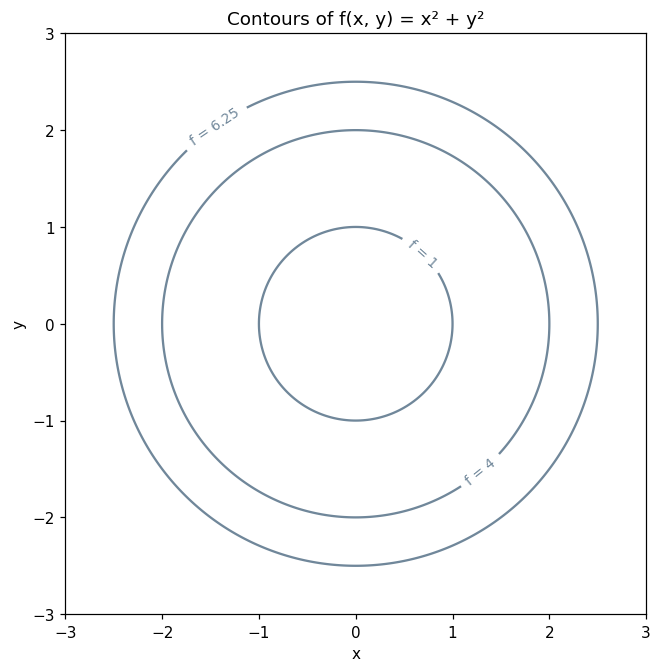

In [10]:
gradient_figure, max_dot = calc.plot_gradient()
contour_axes = gradient_figure.axes[0]
arrows = next(artist for artist in contour_axes.collections if isinstance(artist, Quiver))
tangents = list(contour_axes.lines)
arrows.set_visible(False)
for tangent in tangents:
    tangent.set_visible(False)
contour_axes.get_legend().set_visible(False)
contour_axes.set_title("Contours of f(x, y) = x² + y²")
show_figure(gradient_figure)

### 2-3. 여러 점에 그래디언트 화살표 표시

**과제 요구서 원문**

> 등고선 위 여러 점에서 Gradient 방향을 화살표로 표시한다

$\nabla f(x,y)=(2x,2y)$는 함수값이 가장 빠르게 증가하는 방향이다. 두 등고선의 16개 점에서 화살표가 원점 바깥을 향한다. 화살표 길이는 그림에 맞춰 같은 비율로 줄였다.

$\nabla f=(\partial f/\partial x,\partial f/\partial y)$의 각 성분은 해당 좌표만 조금 움직였을 때의 변화율이다. 예를 들어 $(1,0)$에서는 $(2,0)$이라 오른쪽으로 움직일 때 값이 증가한다. 단위벡터 $u$ 방향의 변화율 $\nabla f\cdot u$는 그래디언트 방향에서 가장 크다. 따라서 손실을 줄이는 경사하강법은 이 화살표의 반대쪽으로 움직인다.

그래디언트를 표시한 점 16개


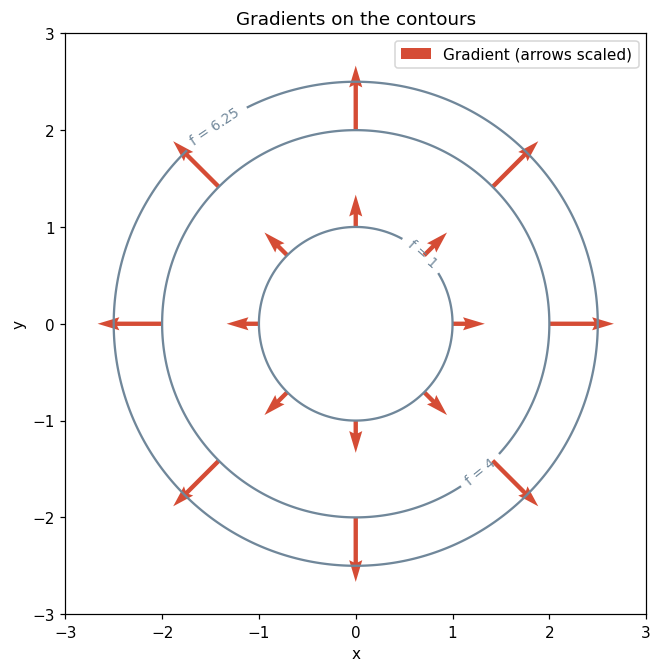

In [11]:
arrows.set_visible(True)
contour_axes.legend(handles=[arrows], loc="upper right")
contour_axes.set_title("Gradients on the contours")
print(f"그래디언트를 표시한 점 {arrows.U.size}개")
show_figure(gradient_figure)

### 2-4. 그래디언트와 등고선의 직교 확인

**과제 요구서 원문**

> Gradient 화살표가 등고선에 수직임을 시각적으로 확인한다

$(x,y)$에서 등고선의 접선 방향은 $(-y,x)$다. 그래디언트와의 내적은 $(2x)(-y)+(2y)x=0$이다. 붉은 화살표와 파란 접선의 각도를 보고, 16개 점에서 단위 접선과의 내적이 0에 가까운지 확인한다.

접선 방향으로 아주 조금 움직이면 함수값의 1차 변화는 $\nabla f\cdot u=0$이다. 예를 들어 $(1,0)$에서 파란 접선은 세로 방향이고 붉은 그래디언트는 가로 방향이다. 손실을 유지하는 방향과 손실을 가장 빠르게 바꾸는 방향이 그림에서 직각으로 만난다.

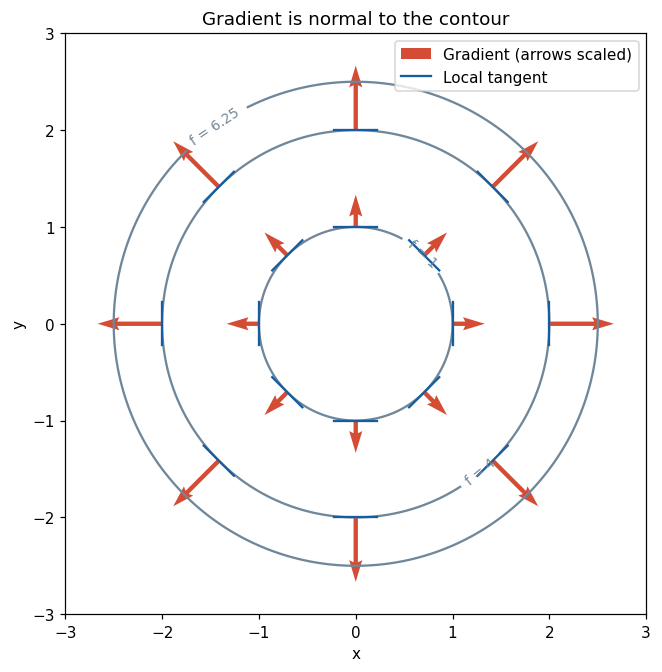

최대 |그래디언트 · 단위 접선| = 0.000e+00  [충족]


In [12]:
for tangent in tangents:
    tangent.set_visible(True)
contour_axes.legend(loc="upper right")
contour_axes.set_title("Gradient is normal to the contour")
assert max_dot <= 1e-12
show_figure(gradient_figure)
print(f"최대 |그래디언트 · 단위 접선| = {max_dot:.3e}  [충족]")

## 3. 역전파: 연쇄 법칙 수식 유도

### 3-1. 입력 2개 → 은닉 2개 → 출력 1개의 순전파 식

**과제 요구서 원문**

> 2층 신경망(입력 2개 → 은닉 2개 → 출력 1개)의 순전파 수식을 노트북에 작성한다

열벡터 규약으로 은닉층과 출력층의 가중합에 각각 $\sigma(t)=1/(1+e^{-t})$를 적용한다. 모델은 이진 분류 확률 $\hat y$를 내놓고 BCE로 손실을 계산한다.

$$z_1=W_1x+b_1,\qquad a_1=\sigma(z_1),\qquad
z_2=W_2^\top a_1+b_2,\qquad \hat y=\sigma(z_2).$$
$$L=-[y\log\hat y+(1-y)\log(1-\hat y)].$$

$z_1,a_1$은 길이 2의 벡터, $z_2,\hat y,L$은 스칼라다.

입력층의 두 값은 첫 번째 가중치 행렬의 각 행과 내적된다. 첫째 행은 은닉 뉴런 1의 가중치 두 개, 둘째 행은 은닉 뉴런 2의 가중치 두 개다. 이 예제의 **2층**은 가중치를 가진 은닉층과 출력층을 가리킨다. 은닉 활성값 $a_1$의 두 성분에 출력층의 가중치를 각각 곱해 더하면 스칼라 $z_2$가 된다. 이를 시그모이드에 넣으면 $0<\hat y<1$인 클래스 1의 확률이 된다. 순전파에서 구한 $a_1$과 $\hat y$는 3-5에서 시그모이드 미분을 계산할 때 다시 쓴다.

### 3-2. 출력에서 입력 쪽으로 연쇄 법칙 적용

**과제 요구서 원문**

> 출력층에서 입력층 방향으로 연쇄 법칙을 적용하여 역전파 수식을 단계별로 유도한다

$\sigma'(t)=\sigma(t)(1-\sigma(t))$를 사용한다. 손실에 가까운 확률의 미분부터 구하고, 앞 단계의 기울기에 현재 연산의 미분을 곱한다.

1. BCE를 $\hat y$로 미분하면 $-y/\hat y+(1-y)/(1-\hat y)$다.
2. $\partial\hat y/\partial z_2=\hat y(1-\hat y)$를 곱하면 $\delta_2=\partial L/\partial z_2=\hat y-y$로 정리된다.
3. $z_2$를 $W_2$와 $a_1$로 각각 미분한 값 $a_1$과 $W_2$에 $\delta_2$를 곱한다.
4. $a_1$에 도달한 기울기에 $a_1\odot(1-a_1)$을 성분별로 곱해 $\delta_1=\nabla_{z_1}L$을 구한다.
5. $z_{1,i}$를 $W_{1,ij}$로 미분하면 $x_j$이므로 $\partial L/\partial W_{1,ij}=\delta_{1,i}x_j$다.

**한 가중치가 손실에 미치는 경로를 먼저 찾는다.** 예를 들어 $W_{1,21}$은 은닉 뉴런 2의 $z_{1,2}$를 거쳐 $a_{1,2}$, $z_2$, $\hat y$, $L$에 영향을 준다. 경로의 각 단계에 대한 변화율을 곱하면
$$
\frac{\partial L}{\partial W_{1,21}}
=\frac{\partial L}{\partial\hat y}
 \frac{\partial\hat y}{\partial z_2}
 \frac{\partial z_2}{\partial a_{1,2}}
 \frac{\partial a_{1,2}}{\partial z_{1,2}}
 \frac{\partial z_{1,2}}{\partial W_{1,21}}
=\delta_2\,W_{2,2}\,a_{1,2}(1-a_{1,2})\,x_1.
$$
같은 은닉 뉴런으로 들어가는 다른 가중치에도 $\delta_{1,2}=\delta_2 W_{2,2}a_{1,2}(1-a_{1,2})$가 공통으로 들어간다. 이 값을 한 번 구해 각 입력 $x_j$와 곱하면 그 행의 모든 가중치 기울기를 얻는다.

### 3-3. 고정 예제의 순전파를 손으로 계산

**과제 요구서 원문**

> 구체적인 숫자 예제로 순전파를 손계산한다
>
> - 입력: x = [1, 0]
> - 가중치 1: W1 = [[0.1, 0.2], [0.3, 0.4]]
> - 편향 1: b1 = [0, 0]
> - 가중치 2: W2 = [0.5, 0.6]
> - 편향 2: b2 = 0
> - 활성화 함수: Sigmoid
> - 손실 함수: Binary Cross-Entropy (BCE) L = -(y·log(ŷ) + (1-y)·log(1-ŷ))
> - 정답: y_true =

원문 3쪽에서 비어 있는 정답은 7쪽 예시에 따라 $y=1$로 둔다. 계산 도중에는 자릿수를 유지하고 표시할 때 반올림한다.

| 단계 | 대입과 손계산 결과 |
| --- | --- |
| 고정 입력 | $x=[1,0]$, $W_1=\begin{bmatrix}0.1&0.2\\0.3&0.4\end{bmatrix}$, $b_1=[0,0]$, $W_2=[0.5,0.6]$, $b_2=0$ |
| 은닉 가중합 | $z_1=[0.1(1)+0.2(0),\,0.3(1)+0.4(0)]=[0.1,0.3]$ |
| 은닉 활성값 | $a_1=[1/(1+e^{-0.1}),\,1/(1+e^{-0.3})]\approx[0.52497919,0.57444252]$ |
| 출력 가중합 | $z_2=0.5(0.52497919)+0.6(0.57444252)+0\approx0.60715510$ |
| 예측 확률 | $\hat y=1/(1+e^{-0.60715510})\approx0.64729157$ |
| BCE | $L=-\log(0.64729157)\approx0.43495844$ |

손으로 따라갈 때는 먼저 $x=[1,0]$이므로 $W_1$의 **첫 번째 열**만 남는다는 점을 이용한다. $\sigma(0.1)$과 $\sigma(0.3)$를 각각 계산한 뒤 출력층에서 0.5와 0.6으로 가중합한다. $y=1$에서는 $(1-y)\log(1-\hat y)$가 사라져 $L=-\log\hat y$다. 표에 보이는 값은 반올림되어 있으므로, 3-5의 네 자리 결과를 검산할 때는 계산기나 코드의 중간값을 가능한 한 그대로 사용한다.

### 3-4. 순전파 중간값 기록

**과제 요구서 원문**

> 순전파 중간값: z1, a1, z2, y_pred 각각을 기록한다

과제에 지정된 네 체크포인트 $z_1,a_1,z_2,\hat y$를 계산 순서대로 표시한다. `backprop_derivation.ipynb`의 NumPy 계산을 그대로 사용한다.

출력의 첫 두 줄은 은닉 뉴런 두 개의 **활성화 전과 후**, 다음 두 줄은 출력 뉴런 하나의 **활성화 전과 후**다. $z_2\approx0.6072$는 로짓이고, $\hat y\approx0.6473$이 클래스 1의 예측 확률이다. 역전파에서는 $z_2$의 기울기와 확률에 대한 기울기를 구분한다.

In [13]:
import numpy as np

np.random.seed(42)

def sigmoid(z):
    """시그모이드 1 / (1 + exp(-z))를 계산한다."""
    return 1 / (1 + np.exp(-z))

x = np.array([1.0, 0.0])
w1 = np.array([[0.1, 0.2], [0.3, 0.4]])
b1 = np.zeros(2)
w2 = np.array([0.5, 0.6])
b2, y = 0.0, 1.0

z1 = w1 @ x + b1
a1 = sigmoid(z1)
z2 = w2 @ a1 + b2
y_pred = sigmoid(z2)
loss = -(y * np.log(y_pred) + (1 - y) * np.log1p(-y_pred))

d_y = -y / y_pred + (1 - y) / (1 - y_pred)
d_z2 = d_y * y_pred * (1 - y_pred)
np.testing.assert_allclose(d_z2, y_pred - y, atol=1e-14, rtol=0)
d_w2 = d_z2 * a1
d_a1 = d_z2 * w2
d_z1 = d_a1 * a1 * (1 - a1)
d_w1 = np.outer(d_z1, x)
d_b2, d_b1 = d_z2, d_z1

for name, value in (("z1", z1), ("a1", a1), ("z2", z2), ("y_pred", y_pred)):
    print(f"{name:7s} shape={str(np.shape(value)):6s} {value}")

z1      shape=(2,)   [0.1 0.3]
a1      shape=(2,)   [0.52497919 0.57444252]
z2      shape=()     0.6071551038264654
y_pred  shape=()     0.6472915699946178


### 3-5. 역전파 필수 기울기 6개 유도

**과제 요구서 원문**

> 역전파 필수 유도 : ∂L/∂y_pred, ∂L/∂z2, ∂L/∂W2, ∂L/∂a1, ∂L/∂z1, ∂L/∂W1 모두 유도한다

3-2의 연쇄 법칙에 3-3의 수치를 대입한다. $\odot$는 성분별 곱이다. 손계산을 네 자리로 반올림하면 다음과 같다.

| 미분 대상 | 유도식 | 손계산 |
| --- | --- | --- |
| $\hat y$ | $\partial L/\partial\hat y=-y/\hat y+(1-y)/(1-\hat y)$ | $-1.5449$ |
| $z_2$ | $\delta_2=(\partial L/\partial\hat y)\hat y(1-\hat y)=\hat y-y$ | $-0.3527$ |
| $W_2$ | $\nabla_{W_2}L=\delta_2a_1$ | $[-0.1852,-0.2026]$ |
| $a_1$ | $\nabla_{a_1}L=\delta_2W_2$ | $[-0.1764,-0.2116]$ |
| $z_1$ | $\delta_1=\nabla_{a_1}L\odot a_1\odot(1-a_1)$ | $[-0.0440,-0.0517]$ |
| $W_1$ | $\nabla_{W_1}L=\delta_1x^\top$ | $\begin{bmatrix}-0.0440&0\\-0.0517&0\end{bmatrix}$ |

편향 미분은 $\partial L/\partial b_2=\delta_2$, $\nabla_{b_1}L=\delta_1$이다. $x$의 둘째 성분이 0이므로 $\nabla_{W_1}L$의 두 번째 열도 0이다.

**수치를 직접 대입해 가중치별 기울기 구하기**

1. $y=1$이므로 $\partial L/\partial\hat y=-1/0.64729157\approx-1.54489885$다. 여기에 $\hat y(1-\hat y)$를 곱하면 $\delta_2\approx-0.35270843$이다. 대수적으로는 $[-y/\hat y+(1-y)/(1-\hat y)]\hat y(1-\hat y)=-y(1-\hat y)+(1-y)\hat y=\hat y-y$다.
2. $z_2=W_{2,1}a_{1,1}+W_{2,2}a_{1,2}+b_2$이므로 $W_{2,1}$과 $W_{2,2}$를 하나씩 바꿨을 때 $z_2$의 변화율은 각각 $0.52497919$와 $0.57444252$다. 두 값에 $\delta_2$를 곱해 $[-0.18516459,-0.20261072]$를 얻는다. 반대로 $a_{1,1}$과 $a_{1,2}$가 바뀔 때의 변화율은 가중치 $[0.5,0.6]$이므로 $\nabla_{a_1}L\approx[-0.17635422,-0.21162506]$이다.
3. 은닉 시그모이드의 기울기는 두 뉴런에서 각각 약 $0.24937604$, $0.24445831$이다. 같은 위치끼리 곱해서 $\delta_1\approx[-0.04397852,-0.05173350]$을 얻는다. 두 번째 성분만 따로 계산하면 $(-0.21162506)(0.57444252)(1-0.57444252)\approx-0.05173350$이다.
4. 첫 층에서는 $z_{1,i}=W_{1,i1}x_1+W_{1,i2}x_2+b_{1,i}$이다. 은닉 뉴런 1의 행은 $-0.04397852[1,0]$이고 뉴런 2의 행은 $-0.05173350[1,0]$이다. 이 두 행을 쌓으면 $W_1$의 네 가중치에 대한 기울기가 된다. 예를 들어 $W_{1,21}$의 기울기가 음수이므로, 다른 값을 고정하고 이 가중치를 조금 키우면 이 표본의 손실이 작아진다.

### 3-6. 각 단계의 shape 확인

**과제 요구서 원문**

> 각 단계에서 텐서의 shape을 반드시 표기한다 (예: W1: (2,2), x: (2,), z1: (2,) 등)

첫 층의 `(2, 2) @ (2,)`는 `(2,)`를, 출력층의 `(2,) @ (2,)`는 스칼라 `()`를 만든다. 역전파에서는 변수와 해당 변수에 대한 기울기의 shape가 같다. 첫 층 가중치 기울기는 길이 2인 두 벡터의 외적이므로 `(2, 2)`다.

행과 열의 의미를 확인하면 외적의 순서도 검산할 수 있다. $\delta_1$을 열로, $x^\top$를 행으로 두면 $(2,1)(1,2)\to(2,2)$이며 각 행은 은닉 뉴런, 각 열은 입력 성분이다. 순서를 뒤집은 $x\delta_1^\top$도 이 예제에서는 shape가 같지만 행·열의 의미와 값이 달라진다. shape 검사와 3-7의 값 비교가 모두 필요한 이유다.

In [14]:
for expected_shape, quantities in (
    ((2,), {"x": x, "b1": b1, "W2": w2, "z1": z1, "a1": a1,
             "dL/dW2": d_w2, "dL/da1": d_a1, "dL/dz1": d_z1, "dL/db1": d_b1}),
    ((2, 2), {"W1": w1, "dL/dW1": d_w1}),
    ((), {"b2": b2, "y": y, "z2": z2, "y_pred": y_pred, "L": loss,
          "dL/dy_pred": d_y, "dL/dz2": d_z2, "dL/db2": d_b2}),
):
    for name, value in quantities.items():
        assert np.shape(value) == expected_shape, name
        print(f"{name:11s} {np.shape(value)}")
print("입력·파라미터·중간값·기울기의 shape 확인  [충족]")

x           (2,)
b1          (2,)
W2          (2,)
z1          (2,)
a1          (2,)
dL/dW2      (2,)
dL/da1      (2,)
dL/dz1      (2,)
dL/db1      (2,)
W1          (2, 2)
dL/dW1      (2, 2)
b2          ()
y           ()
z2          ()
y_pred      ()
L           ()
dL/dy_pred  ()
dL/dz2      ()
dL/db2      ()
입력·파라미터·중간값·기울기의 shape 확인  [충족]


### 3-7. 손계산과 NumPy 결과를 소수점 4자리까지 비교

**과제 요구서 원문**

> NumPy 코드로 동일한 계산을 수행하고, 손계산 결과와 소수점 4자리까지 일치함을 확인한다

손계산 표의 값과 NumPy 출력을 소수점 넷째 자리에서 비교한다. 원문 7쪽의 표시값을 재계산해 $z_2$는 $0.6072$, $\delta_1$의 둘째 값은 $-0.0517$로 확인했다.

출력에서 $W_2$의 두 값과 $W_1$의 네 값을 하나씩 대조한다. 두 번째 입력이 0이라서 $W_1$의 두 번째 열은 두 행 모두 0이어야 한다. 출력의 `-0.0000`은 부동소수점의 부호 있는 0으로, 이 비교에서는 `0.0000`과 같은 값이다. 손계산으로 예측한 가중치별 부호와 0의 위치까지 확인해 보자.

In [15]:
# 앞에서 유도한 4자리 손계산 값을 별도로 입력한다.
expected = {
    "z1": ([0.1, 0.3], z1),
    "a1": ([0.5250, 0.5744], a1),
    "z2": (0.6072, z2),
    "y_pred": (0.6473, y_pred),
    "L": (0.4350, loss),
    "dL/dy_pred": (-1.5449, d_y),
    "dL/dz2": (-0.3527, d_z2),
    "dL/dW2": ([-0.1852, -0.2026], d_w2),
    "dL/da1": ([-0.1764, -0.2116], d_a1),
    "dL/dz1": ([-0.0440, -0.0517], d_z1),
    "dL/dW1": ([[-0.0440, 0], [-0.0517, 0]], d_w1),
    "dL/db1": ([-0.0440, -0.0517], d_b1),
    "dL/db2": (-0.3527, d_b2),
}

for name, (hand, actual) in expected.items():
    computed = np.round(actual, 4)
    np.testing.assert_array_equal(computed, hand)
    formatter = {"float_kind": lambda value: f"{value:.4f}"}
    hand_text = np.array2string(np.asarray(hand), formatter=formatter)
    numpy_text = np.array2string(np.asarray(computed), formatter=formatter)
    print(f"{name:11s} 손계산 {hand_text.replace(chr(10), ' ')}   NumPy {numpy_text.replace(chr(10), ' ')}")
print(f"{len(expected)}개 항목 모두 소수점 넷째 자리까지 일치  [충족]")

z1          손계산 [0.1000 0.3000]   NumPy [0.1000 0.3000]
a1          손계산 [0.5250 0.5744]   NumPy [0.5250 0.5744]
z2          손계산 0.6072   NumPy 0.6072
y_pred      손계산 0.6473   NumPy 0.6473
L           손계산 0.4350   NumPy 0.4350
dL/dy_pred  손계산 -1.5449   NumPy -1.5449
dL/dz2      손계산 -0.3527   NumPy -0.3527
dL/dW2      손계산 [-0.1852 -0.2026]   NumPy [-0.1852 -0.2026]
dL/da1      손계산 [-0.1764 -0.2116]   NumPy [-0.1764 -0.2116]
dL/dz1      손계산 [-0.0440 -0.0517]   NumPy [-0.0440 -0.0517]
dL/dW1      손계산 [[-0.0440 0.0000]  [-0.0517 0.0000]]   NumPy [[-0.0440 -0.0000]  [-0.0517 -0.0000]]
dL/db1      손계산 [-0.0440 -0.0517]   NumPy [-0.0440 -0.0517]
dL/db2      손계산 -0.3527   NumPy -0.3527
13개 항목 모두 소수점 넷째 자리까지 일치  [충족]


### 과제 목표 3 정리 — 연쇄 법칙과 가중치 기울기 손계산

**목표 원문**  
연쇄 법칙을 사용하여 2층 신경망의 역전파 수식을 유도하고, 각 가중치에 대한 기울기를 손계산할 수 있다

순전파에서 $x=[1,0]$을 넣으면 $a_1\approx[0.5250,0.5744]$, $\hat y\approx0.6473$을 얻는다. 역전파에서는 손실과 가장 가까운 출력 로짓부터 시작해, 이미 구한 기울기에 각 연산의 미분을 곱한다. BCE와 시그모이드의 미분을 합친 $\delta_2=\hat y-y\approx-0.3527$이 출발점이다.

출력층에서는 각 가중치에 연결된 활성값을 곱해 $\nabla_{W_2}L=\delta_2a_1\approx[-0.1852,-0.2026]$을 얻는다. 은닉층으로 전달할 때는 출력 가중치와 은닉 시그모이드 미분을 곱해 $\delta_1=\delta_2 W_2\odot a_1\odot(1-a_1)\approx[-0.0440,-0.0517]$을 얻는다. 첫 층의 각 가중치 기울기는 $\delta_{1,i}x_j$다. 두 행에 입력 $[1,0]$을 곱하면 첫 열은 $[-0.0440,-0.0517]$, 둘째 열은 $[0,0]$이다. `3-7`의 출력에서 손계산과 NumPy의 값이 소수점 넷째 자리까지 일치한다.

**스스로 설명하기** — $W_{1,21}$의 변화가 손실에 닿는 경로의 미분을 순서대로 곱하고, $W_{1,22}$의 기울기는 왜 0인지 설명한다.

## 4. 최적화: 경사하강법 시각화

### 4-1. Vanilla GD를 원형 함수에 적용

**과제 요구서 원문**

> Vanilla GD를 구현하고 f(x,y)=x²+y²에 적용한다

$f(x,y)=x^2+y^2$에서 $\nabla f=(2x,2y)$이므로 `VanillaGD.step()`은 $p_{t+1}=p_t-\eta(2p_t)$로 좌표를 갱신한다. $(5,5)$에서 시작해 학습률 0.1로 첫 두 번의 좌표가 각각 $(4,4)$, $(3.2,3.2)$인지 확인한다.

$\eta$는 그래디언트 방향으로 움직이는 양을 조절하는 **학습률**이다. 손실을 줄이려면 그래디언트를 빼므로, 첫 단계는 $(5,5)-0.1(10,10)=(4,4)$다. 다음 단계는 새 위치의 기울기를 다시 계산해 $(4,4)-0.1(8,8)=(3.2,3.2)$가 된다. 아래 결과의 각 좌표가 이전 값의 0.8배라는 사실을 4-2와 4-4의 계산에 사용한다.

In [16]:
start = np.array([5.0, 5.0])
gd_path = opt.trajectory(opt.VanillaGD(0.1), opt.quadratic_gradient, start, 100)
np.testing.assert_allclose(gd_path[:3], [[5, 5], [4, 4], [3.2, 3.2]])
for step, point in enumerate(gd_path[:3]):
    print(f"{step}회: {point}  f={opt.quadratic_loss(point):.4f}")

0회: [5. 5.]  f=50.0000
1회: [4. 4.]  f=32.0000
2회: [3.2 3.2]  f=20.4800


### 4-2. 100회 후 원점으로부터의 거리 확인

**과제 요구서 원문**

> lr=0.1, 100회 반복 후 (x,y)가 원점 근처(반경 0.1 이내)에 도달함을 확인한다

초기점은 0번째 위치다. 100번째 업데이트의 좌표에 대해 $\sqrt{x^2+y^2}$를 구하고 반경 **0.1 이내**인지 검사한다.

이 함수에서 학습률 0.1이면 $p_t=0.8^t(5,5)$다. 그래서 100회 후의 두 좌표는 각각 $5(0.8)^{100}\approx1.0185\times10^{-9}$이고 원점까지 거리는 $\sqrt2$배인 약 $1.4404\times10^{-9}$다. 출력과 비교하면 코드가 작은 손실값뿐 아니라 요구된 **위치의 거리**도 충족함을 확인할 수 있다.

In [17]:
assert len(gd_path) == 101
radius = np.linalg.norm(gd_path[-1])
assert radius <= 0.1
print(f"100회 후 좌표={gd_path[-1]}  원점 거리={radius:.6e}  [충족]")

100회 후 좌표=[1.01851799e-09 1.01851799e-09]  원점 거리=1.440402e-09  [충족]


### 4-3. 등고선 위에 Vanilla GD 경로 표시

**과제 요구서 원문**

> 수렴 경로를 등고선 위에 점선으로 출력한다

왼쪽의 파란 점선은 $(5,5)$에서 시작해 등고선을 통과하는 경로다. 오른쪽에서 100회 동안 목적함수가 줄어드는 모습을 함께 확인한다.

왼쪽 경로는 $x=y$ 직선에 놓인다. 두 좌표에 매번 같은 배율이 적용되기 때문이다. 오른쪽에서 손실이 줄어드는 비율은 거리 비율 0.8의 제곱인 0.64다. 초반의 $50\to32\to20.48$이 그 관계를 보여 준다. 두 그래프를 함께 보면 **어디로 움직이는지**와 **반복할 때 손실이 얼마나 줄었는지**를 각각 설명할 수 있다.

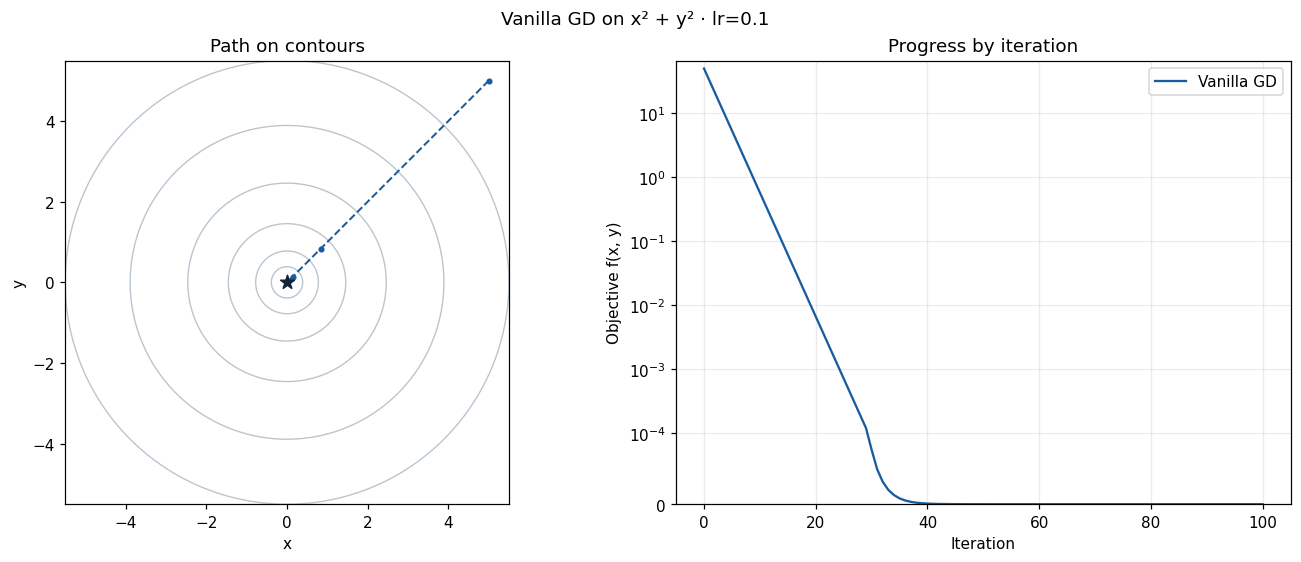

In [18]:
gd_figure = opt.plot_convergence({"Vanilla GD": gd_path}, 1,
                                  "Vanilla GD on x² + y² · lr=0.1")
show_figure(gd_figure)

### 4-4. 학습률이 큰 구간에서 수렴·진동·발산 비교

**과제 요구서 원문**

> lr=0.5 이상에서 최적화 경로가 발산함을 그래프로 확인한다

원문은 $\eta\ge0.5$에서 발산을 확인하라고 한다. 이 함수의 갱신식은 $p_{t+1}=(1-2\eta)p_t$이다. 따라서 $0<\eta<1$이면 거리가 줄고, $\eta=1$이면 거리가 일정하며, $\eta>1$이면 거리가 커진다. $\eta=0.5$에서는 배율이 0이다. 왼쪽 경로의 방향과 오른쪽 거리의 증감을 함께 비교한다.

원점이 아닌 곳에서 시작하면 $t$회 후 거리는 $\|p_t\|=|1-2\eta|^t\|p_0\|$이다. **배율의 부호는 매번 원점을 넘는지를, 절댓값은 거리가 줄어드는지를 결정한다.**

| 학습률 $\eta$ | 좌표 배율 $1-2\eta$ | 오른쪽 거리 그래프에서 볼 결과 |
| --- | ---: | --- |
| 0.5 | 0 | 첫 이동에서 거리가 0 |
| 0.75 | -0.5 | 방향이 번갈아 바뀌며 거리는 매번 절반 |
| 1.0 | -1 | 두 점을 왕복하며 거리는 일정 |
| 1.1 | -1.2 | 방향이 번갈아 바뀌며 거리는 매번 1.2배 |

따라서 양의 학습률에서 발산 조건은 $|1-2\eta|>1$, 즉 $\eta>1$이다. 예를 들어 $1.1$에서 $12$회 후 거리 $5\sqrt{2}(1.2)^{12}\approx63.05$는 아래 수치와 일치한다.

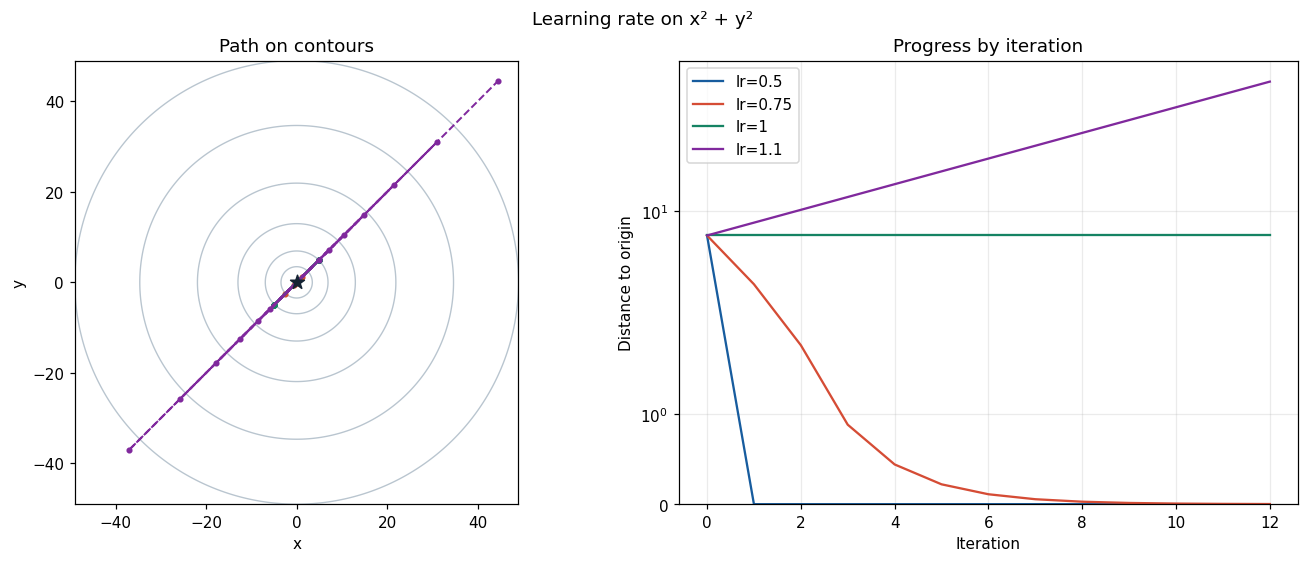

lr=0.5   첫 거리=0.000000  12회 후=0.000000  한 번에 원점 도달
lr=0.75  첫 거리=3.535534  12회 후=0.001726  원점을 넘으며 수렴
lr=1     첫 거리=7.071068  12회 후=7.071068  두 점 사이 왕복
lr=1.1   첫 거리=8.485281  12회 후=63.046351  발산
실제 발산 조건: lr > 1  [원문 조건과 불일치]


In [19]:
rate_paths = {
    f"lr={rate:g}": opt.trajectory(opt.VanillaGD(rate), opt.quadratic_gradient, start, 12)
    for rate in (0.5, 0.75, 1, 1.1)
}
radii = {label: np.linalg.norm(path, axis=1) for label, path in rate_paths.items()}
assert radii["lr=0.5"][1] == 0
assert np.all(np.diff(radii["lr=0.75"]) < 0)
np.testing.assert_allclose(rate_paths["lr=1"][1:], -rate_paths["lr=1"][:-1])
assert np.all(np.diff(radii["lr=1.1"]) > 0)
show_figure(opt.plot_convergence(rate_paths, 1, "Learning rate on x² + y²", metric="radius"))
for (label, values), behavior in zip(radii.items(),
                                      ("한 번에 원점 도달", "원점을 넘으며 수렴", "두 점 사이 왕복", "발산")):
    print(f"{label:8s} 첫 거리={values[1]:.6f}  12회 후={values[-1]:.6f}  {behavior}")
print("실제 발산 조건: lr > 1  [원문 조건과 불일치]")

### 4-5. Momentum(β=0.9)과 Vanilla GD 비교

**과제 요구서 원문**

> Momentum(beta=0.9)을 구현하고 Vanilla GD와 수렴 경로를 비교한다

Momentum은 $v_{t+1}=0.9v_t+\nabla f(p_t)$를 먼저 계산하고 $p_{t+1}=p_t-\eta v_{t+1}$로 이동한다. $v_0=0$이므로 첫 이동은 같고, 두 번째부터는 이전 속도가 반영된다. 같은 초기점과 학습률 0.1에서 손실이 0.01 이하로 내려가 마지막 반복까지 유지되는 시점을 비교한다.

첫 속도는 $v_1=(10,10)$이라 두 방식 모두 $(4,4)$로 간다. 두 번째 위치의 기울기는 $(8,8)$이다. GD는 이 기울기만 써서 $(3.2,3.2)$로 가고, Momentum은 $v_2=0.9(10,10)+(8,8)=(17,17)$이므로 $(2.3,2.3)$으로 간다. 연속해서 같은 방향의 기울기가 나오면 이전 속도가 누적된다. 원점을 넘어 기울기가 바뀌면 기존 속도 때문에 방향 전환이 늦어질 수 있다. 초반에 더 멀리 움직인 것과 마지막까지 낮은 손실을 유지하는 시점의 차이는 4-6에서 확인한다.

In [20]:
momentum_path = opt.trajectory(opt.Momentum(0.1, beta=0.9), opt.quadratic_gradient,
                               start, 100)
np.testing.assert_allclose(momentum_path[1], gd_path[1])
np.testing.assert_allclose(momentum_path[2], [2.3, 2.3])
circle_paths = {"Vanilla GD": gd_path, "Momentum (beta=0.9)": momentum_path}
loss_threshold = 0.01
for name, path in circle_paths.items():
    losses = opt.quadratic_loss(path)
    sustained = opt.sustained_step(losses, loss_threshold)
    print(f"{name:20s} 2회 후={path[2]}  기준 유지 시작={sustained}회  "
          f"100회 후 손실={losses[-1]:.3e}")

Vanilla GD           2회 후=[3.2 3.2]  기준 유지 시작=20회  100회 후 손실=2.075e-18
Momentum (beta=0.9)  2회 후=[2.3 2.3]  기준 유지 시작=77회  100회 후 손실=4.065e-04


### 4-6. 두 수렴 경로를 한 Figure에 겹쳐 표시

**과제 요구서 원문**

> 두 옵티마이저의 수렴 경로를 하나의 Figure에 겹쳐 출력한다

같은 원형 등고선 위에 GD와 Momentum을 겹쳐 그린다. 두 경로의 차이는 두 번째 업데이트부터 나타난다. 이 설정에서 GD는 원점에 바로 접근하고, Momentum은 원점을 지나 왕복해 오른쪽 손실 곡선이 출렁인다.

두 방식 모두 같은 대각선에서 이동하므로, 겹친 공간 경로만 보면 어느 쪽이 먼저 안정되는지 판단하기 어렵다. 오른쪽에서 손실 0.01을 처음 한 번 통과한 시점과 **그 이후 계속 아래에 있는 시점**을 구분한다. 이 원형 예제와 학습률 0.1에서는 GD가 20회째부터, Momentum은 원점 주위를 진동하다 77회째부터 기준 이하를 유지한다. 4-7은 두 방향의 곡률이 다를 때 같은 기준의 비교가 어떻게 달라지는지 보여 준다.

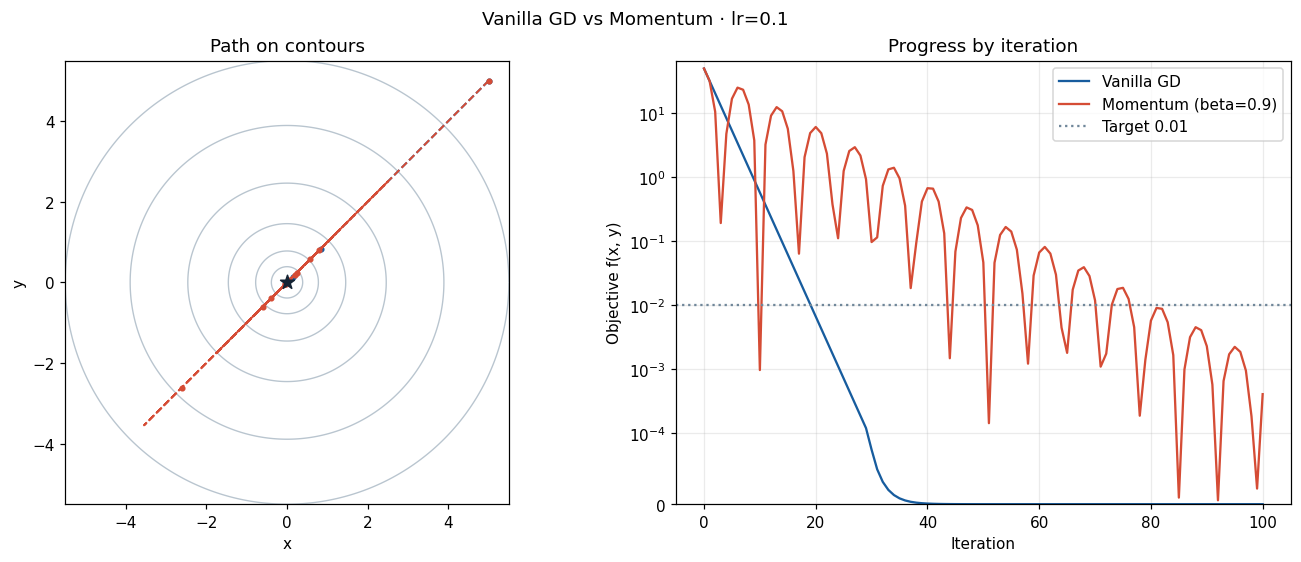

In [21]:
show_figure(opt.plot_convergence(circle_paths, 1, "Vanilla GD vs Momentum · lr=0.1",
                                 threshold=loss_threshold))

### 4-7. 타원형 함수에서 Momentum의 이점 확인

**과제 요구서 원문**

> 타원형 함수 f(x,y)=x²+10y²에서도 Vanilla GD와 Momentum의 수렴 경로를 비교하여 Momentum의 이점을 확인한다

$f(x,y)=x^2+10y^2$는 $y$ 방향의 기울기가 더 가파르다. 동일한 초기점 $(5,5)$, 학습률 0.01, 200회 업데이트에서 두 경로를 그린다. 오른쪽의 손실 0.01 이하를 **마지막 반복까지 유지하기 시작한 시점**이 빠른 쪽을 확인한다. 원문 예시의 학습률 0.05에서도 같은 지표를 계산한다.

**GD가 느려지는 방향.** 기울기는 $(2x,20y)$여서 같은 학습률에서도 좌표마다 거리 배율이 다르다. $\eta=0.01$에서 $x_{t+1}=0.98x_t$, $y_{t+1}=0.8y_t$다. $y$는 빠르게 0 근처로 가고 $x$는 조금씩만 줄기 때문에, 그래프에서 타원의 긴 축 방향으로 이동하는 구간이 남는다. Momentum은 같은 방향의 갱신이 이어지는 구간에서 이전 기울기를 누적해 그 구간의 이동을 키운다. 손실 0.01 이하를 유지하는 데 걸린 반복은 GD 194회, Momentum 97회로 실제 출력에서 비교할 수 있다.

**학습률을 바꾸면 결과도 바뀐다.** $\eta=0.05$에서 GD의 $y$ 배율은 $1-20(0.05)=0$이어서 첫 이동으로 $y=0$에 도달하고, $x$는 0.9배씩 준다. 이때 같은 기준은 GD 38회, Momentum 97회다. 두 실험에서 본 Momentum의 이점은 함수의 모양과 학습률 조합에 따라 달라진다.

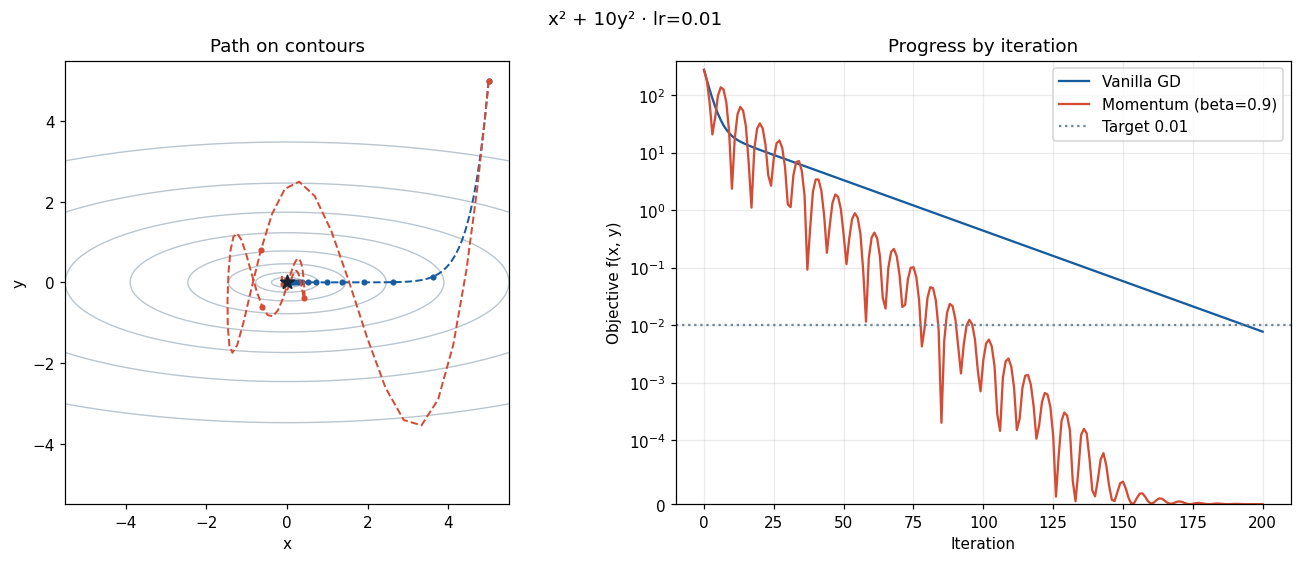

lr=0.01: GD 194회, Momentum 97회
lr=0.05: GD 38회, Momentum 97회
이 실험에서는 lr=0.01에서 Momentum이 기준에 더 빨리 도달함  [조건 표시]


In [22]:
ellipse_gradient = partial(opt.quadratic_gradient, y_weight=10)
for rate, steps in ((0.01, 200), (0.05, 100)):
    paths = {
        "Vanilla GD": opt.trajectory(opt.VanillaGD(rate), ellipse_gradient, start, steps),
        "Momentum (beta=0.9)": opt.trajectory(opt.Momentum(rate, beta=0.9),
                                             ellipse_gradient, start, steps),
    }
    gd_step, momentum_step = (
        opt.sustained_step(opt.quadratic_loss(path, 10), loss_threshold)
        for path in paths.values()
    )
    if rate == 0.01:
        assert momentum_step < gd_step
        show_figure(opt.plot_convergence(paths, 10, "x² + 10y² · lr=0.01",
                                         threshold=loss_threshold))
    print(f"lr={rate:.2f}: GD {gd_step}회, Momentum {momentum_step}회")
print("이 실험에서는 lr=0.01에서 Momentum이 기준에 더 빨리 도달함  [조건 표시]")

### 과제 목표 5 정리 — 학습률과 Momentum이 수렴에 미치는 영향

**목표 원문**  
Learning Rate와 Momentum이 경사하강법 수렴에 미치는 영향을 실험 결과와 함께 설명할 수 있다

원형 함수에서 Vanilla GD는 매번 좌표를 $1-2\eta$배 한다. 배율의 부호는 원점을 넘는지를, 절댓값은 거리가 줄고 늘어나는지를 결정한다. `4-4`의 결과대로 $\eta=0.5$는 한 번에 원점에 도달하고, 0.75는 원점을 넘으며 수렴한다. 1은 같은 거리를 유지하며 왕복하고, 1.1은 왕복할수록 원점에서 멀어진다.

Momentum은 현재 기울기에 이전 속도를 더해 같은 방향으로 이동할 때 보폭을 키운다. 누적된 속도가 크면 원점을 지나 진동할 수도 있다. 같은 손실 기준인 0.01 이하를 마지막까지 유지하기 시작한 시점을 비교하면, 원형 함수의 학습률 0.1에서는 GD 20회와 Momentum 77회다. 타원형 함수의 학습률 0.01에서는 GD가 완만한 $x$ 방향으로 조금씩 움직여 194회가 걸리고, Momentum은 97회에 도달한다. 타원형 함수에서도 학습률을 0.05로 바꾸면 GD의 $y$ 좌표가 한 번에 0이 되어 GD가 38회로 앞선다. **함수의 방향별 가파르기와 학습률**을 함께 봐야 수렴 속도의 차이를 설명할 수 있다.

**스스로 설명하기** — `4-4`에서 네 학습률의 배율을 계산한 뒤, `4-6`과 `4-7`의 같은 손실 기준에서 두 방식의 순서가 왜 바뀌는지 이야기한다.

## 5. 확률/통계: 손실 함수의 수학적 기반

### 5-1. 정규분포 두 종류의 PDF 비교

**과제 요구서 원문**

> 정규분포 N(0,1)과 N(2,0.5)의 PDF 곡선을 하나의 Figure에 비교 출력한다

$\mathcal{N}(\mu,\sigma^2)$의 두 번째 인자는 분산이다. 한 Figure에서 $\mathcal{N}(0,1)$과 $\mathcal{N}(2,0.5)$를 비교하면 두 번째 곡선이 평균 2로 이동하고 분산이 작아 폭이 좁아진다. 세로축은 확률밀도이며 구간 아래의 면적이 확률이다.

회귀에 적용할 때 $\mu_i$는 입력 $x_i$를 보고 모델이 예측한 값이다. 서로 다른 입력에서는 예측값이 달라 밀도 곡선의 중심도 움직인다. 5-4에서는 각 예측값 주위에 같은 분산의 정규분포를 두고, 실제 관측값 $y_i$에서의 **밀도**를 읽어 우도를 계산한다. 관측이 예측값에서 멀어지면 그 밀도가 낮아지고 음의 로그우도는 커진다.

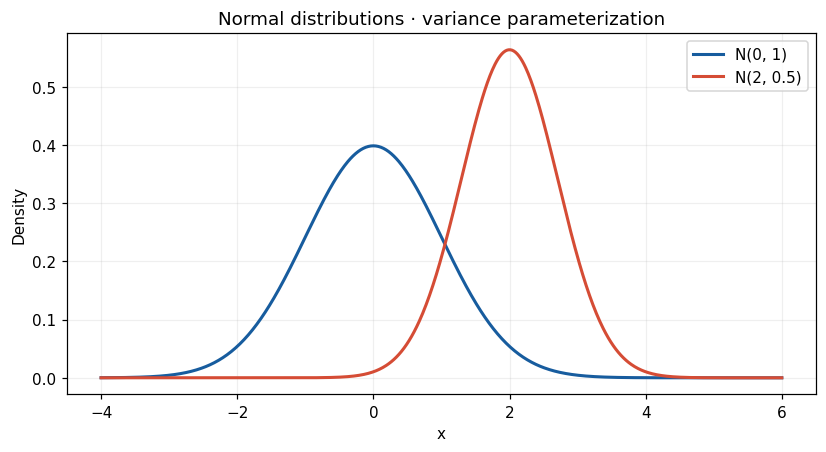

In [23]:
def normal_pdf(x, mean, variance):
    """정규분포의 평균과 분산으로 확률밀도를 계산한다."""
    return np.exp(-(x - mean)**2 / (2 * variance)) / np.sqrt(2 * np.pi * variance)

x = np.linspace(-4, 6, 801)
fig, ax = plt.subplots(figsize=(7.4, 4), layout="constrained")
ax.plot(x, normal_pdf(x, 0, 1), label="N(0, 1)", color="#175c9e", lw=2)
ax.plot(x, normal_pdf(x, 2, 0.5), label="N(2, 0.5)", color="#d54c35", lw=2)
ax.set(title="Normal distributions · variance parameterization", xlabel="x", ylabel="Density")
ax.grid(alpha=0.2)
ax.legend()
show_figure(fig)

### 5-2. 베르누이 분포 두 종류의 PMF 비교

**과제 요구서 원문**

> 베르누이 분포 B(0.3)과 B(0.7)의 PMF 막대그래프를 하나의 Figure에 비교 출력한다

베르누이 분포는 $P(Y=0)=1-p$, $P(Y=1)=p$를 갖는다. $p=0.3$과 $p=0.7$의 막대를 같은 Figure에서 비교한다. 막대는 각 결과의 확률이며 같은 색의 두 막대를 더하면 1이다.

그래프에서 $B(0.7)$이 정답 1에 부여하는 확률은 0.7, 정답 0에 부여하는 확률은 0.3이다. 관측 정답이 0이면 BCE에 들어가는 것은 막대 $P(Y=0)=1-p$이고, 정답이 1이면 $P(Y=1)=p$다. 5-5에서 이 선택을 $p^y(1-p)^{1-y}$ 한 식으로 표현한다.

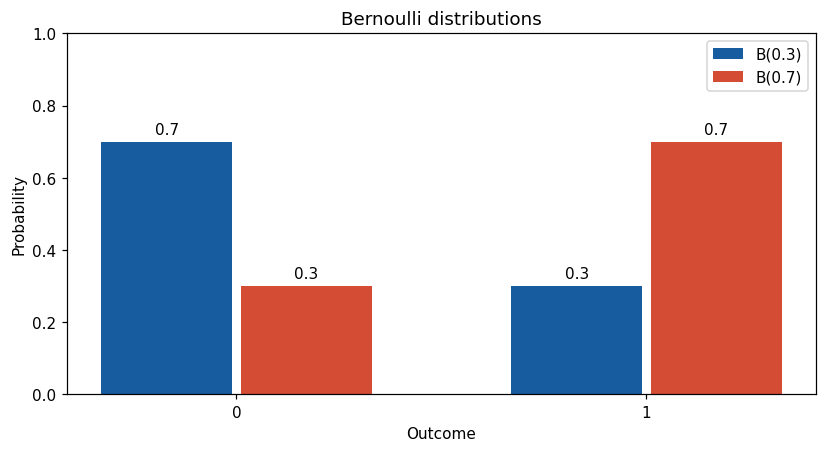

In [24]:
def bernoulli_pmf(p):
    """값 0과 1의 확률 질량을 순서대로 반환한다."""
    return np.array([1 - p, p])

values = np.array([0, 1])
fig, ax = plt.subplots(figsize=(7.4, 4), layout="constrained")
for p, offset, color in ((0.3, -0.17, "#175c9e"), (0.7, 0.17, "#d54c35")):
    bars = ax.bar(values + offset, bernoulli_pmf(p), width=0.32, label=f"B({p})", color=color)
    ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set(title="Bernoulli distributions", xlabel="Outcome", ylabel="Probability",
       xticks=values, ylim=(0, 1))
ax.legend()

for p in (0.3, 0.7):
    np.testing.assert_allclose(bernoulli_pmf(p).sum(), 1)
show_figure(fig)

### 5-3. 소프트맥스 구현과 출력 합 확인

**과제 요구서 원문**

> 소프트맥스 함수를 구현하고, 출력 벡터의 합이 1.0과의 차이가 1e-6 이내임을 확인한다

$p_i=\exp(z_i-m)/\sum_j\exp(z_j-m)$에서 $m=\max(z)$를 빼고 지수를 구하면 큰 로짓에서도 안정적이다. 로짓 `[1000, 1001, 1002]`의 출력 확률 합과 1의 차이가 **$10^{-6}$ 이하**인지 확인한다.

확률 세 개가 모두 같은 분모로 나뉘므로 수학적으로 합이 1이다. 큰 로짓에서는 지수를 계산하기 전에 공통 최댓값을 빼고, 이때 분자·분모에서 같은 곱이 약분되어 확률이 같게 유지된다. 저장된 예시에서 정답이 세 번째 클래스라면 선택할 확률은 0.66524, 첫 번째라면 0.09003이다. 5-5의 손실 $-\log p_{\text{정답}}$에 넣으면 각각 약 0.4076과 2.4076이다. 같은 확률 벡터라도 어느 클래스가 실제 정답이냐에 따라 손실이 달라진다.

In [25]:
def softmax(logits):
    """마지막 축의 최댓값을 빼고 안정적으로 정규화한다."""
    logits = np.asarray(logits, dtype=float)
    exp = np.exp(logits - np.max(logits, axis=-1, keepdims=True))
    return exp / np.sum(exp, axis=-1, keepdims=True)


logits = np.array([1000, 1001, 1002])
probabilities = softmax(logits)
error = abs(probabilities.sum() - 1.0)
assert error <= 1e-6
np.testing.assert_allclose(probabilities, softmax(logits - 1000), atol=1e-14, rtol=0)
print(f"확률={probabilities}  합={probabilities.sum():.15f}  오차={error:.3e}  [충족]")

확률=[0.09003057 0.24472847 0.66524096]  합=1.000000000000000  오차=1.110e-16  [충족]


### 5-4. 정규 오차 가정에서 MSE와 최대우도추정 연결

**과제 요구서 원문**

> "MSE 최소화 = 정규분포 가정 하의 MLE"임을 수식으로 유도하여 노트북에 작성한다

예측값을 $\mu_i=f_\theta(x_i)$, 잔차를 $y_i-\mu_i$라고 하자. 잔차가 서로 독립이고 평균 0과 같은 고정 분산 $\sigma^2>0$을 가진 정규분포라면

$$p(y_i\mid x_i;\theta)=\frac{1}{\sqrt{2\pi\sigma^2}}\exp\!\left(-\frac{(y_i-\mu_i)^2}{2\sigma^2}\right).$$

곱의 음의 로그를 취하면
$$-\log\prod_{i=1}^n p(y_i\mid x_i;\theta)
=\frac{n}{2}\log(2\pi\sigma^2)+\frac{1}{2\sigma^2}\sum_{i=1}^n(y_i-\mu_i)^2
=\frac{n}{2}\log(2\pi\sigma^2)+\frac{n}{2\sigma^2}\operatorname{MSE}.$$

앞 항은 $\theta$에 무관하고 MSE 앞의 계수는 양수다. 따라서 두 목적함수를 최소화하는 $\theta$가 같다. 관측마다 분산이 다르면 제곱 오차에도 서로 다른 가중치가 생긴다.

**우도를 최대화한다는 뜻.** $(x_i,y_i)$를 관측한 뒤 고정하고, $\theta$를 바꿀 때 그 관측에 부여하는 조건부 결합 밀도 $\mathcal L(\theta)=\prod_i p(y_i\mid x_i;\theta)$가 어떻게 바뀌는지 비교한다. 로그는 증가함수이므로 $\mathcal L$을 가장 크게 하는 $\theta$는 $-\log\mathcal L$을 가장 작게 하는 $\theta$와 같다. 로그를 쓰면 독립 관측의 곱이 합으로 바뀐다.

정규분포에서는 음의 로그를 취할 때 각 관측의 지수부 $-(y_i-\mu_i)^2/(2\sigma^2)$에서 **제곱 오차**가 나온다. 데이터와 분산이 고정되어 있으면 위 식의 상수와 양의 배율을 빼고도 최솟값을 내는 $\theta$는 그대로다. 즉 $\arg\max_\theta\mathcal L(\theta)=\arg\min_\theta\operatorname{MSE}(\theta)$다. 아래 예시의 잔차 $(0.2,-0.3,-0.1)$을 제곱해 평균하면 $0.14/3\approx0.046667$이다. 이 값으로 계산한 전체 음의 로그우도 $1.857095$가 각 관측의 밀도로 직접 계산한 값과 일치한다.

In [26]:
observed = np.array([0.2, 1.0, 2.1])
mean = np.array([0.0, 1.3, 2.2])
variance = 0.5
mse = np.mean((observed - mean) ** 2)
nll = -np.log(normal_pdf(observed, mean, variance)).sum()
from_mse = len(observed) / 2 * (np.log(2 * np.pi * variance) + mse / variance)
np.testing.assert_allclose(nll, from_mse)
print(f"MSE={mse:.6f}  직접 구한 음의 로그우도={nll:.6f}  MSE로 구한 값={from_mse:.6f}  [충족]")

MSE=0.046667  직접 구한 음의 로그우도=1.857095  MSE로 구한 값=1.857095  [충족]


### 5-5. 베르누이·카테고리 가정에서 Cross-Entropy와 최대우도추정 연결

**과제 요구서 원문**

> "Cross-Entropy 최소화 = 베르누이/카테고리 분포 가정 하의 MLE"임을 수식으로 유도하여 노트북에 작성한다

**이진 분류.** 모델이 $p_i=P(Y_i=1\mid x_i)$를 내놓으면 실제 답 $y_i\in\{0,1\}$의 확률은 $p_i^{y_i}(1-p_i)^{1-y_i}$이다. 여러 관측의 음의 로그우도는
$$-\log\prod_i p_i^{y_i}(1-p_i)^{1-y_i}
=-\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)] = n\,\overline{\operatorname{BCE}}.$$

**다중 분류.** 정답을 원-핫 벡터 $t_{ic}$로, 모델이 클래스 $c$에 부여한 확률을 $p_{ic}$로 쓰면 정답 확률은 $\prod_c p_{ic}^{t_{ic}}$이다. 음의 로그우도는
$$-\log\prod_i\prod_c p_{ic}^{t_{ic}}
=-\sum_i\sum_c t_{ic}\log p_{ic}=n\,\overline{\operatorname{CE}}.$$

두 경우 모두 실제 정답에 부여한 확률이 낮을수록 $-\log p$가 커진다. 예를 들어 정답 확률이 0.8이면 손실은 약 0.223, 0.2면 약 1.609다.

**출력 수치를 손으로 검산하기.** 이진 예시의 두 관측은 $(y,p)=(1,0.8),(0,0.3)$이다. 각각 실제 정답의 막대에서 0.8과 0.7을 선택하므로 두 정답을 관측할 우도는 $0.8\cdot0.7=0.56$이다. 음의 로그를 취한 $-\log(0.56)\approx0.579818$은 두 BCE의 합과 같다. 다중 분류 예시에서 원-핫 벡터는 관측별 정답 클래스 하나만 고른다. 두 관측에 부여한 정답 확률은 각각 약 0.66524이므로 두 Cross-Entropy의 합은 $-2\log(0.66524)\approx0.815212$다. 표본이 조건부로 독립이라서 우도를 곱하고, 표본 수가 고정되어 합과 평균 중 어느 것을 최소화해도 같은 파라미터를 얻는다.

| 비교 | MSE | Cross-Entropy |
| --- | --- | --- |
| 관측 및 모델 출력 | 연속값 $y$와 예측 평균 $\mu$ | 범주형 정답 $y$와 클래스 확률 |
| 관측에 부여하는 값 | 예측 평균 주변 정규분포의 밀도 | 베르누이 또는 카테고리 분포가 정답에 준 확률 |
| 음의 로그에서 나오는 항 | 고정 계수로 스케일된 $(y-\mu)^2$와 상수 | $-\log P(Y=y\mid x)$ |

3-1의 BCE도 같은 사례다. 그 신경망은 시그모이드로 $P(Y=1\mid x)$를 내고, BCE를 줄이는 방향으로 가중치를 갱신해 이 한 표본의 정답 확률을 높인다.

In [27]:
labels = np.array([1, 0])
probabilities = np.array([0.8, 0.3])
bernoulli_nll = -np.log(probabilities ** labels * (1 - probabilities) ** (1 - labels)).sum()
bce_sum = -np.sum(labels * np.log(probabilities)
                  + (1 - labels) * np.log1p(-probabilities))
np.testing.assert_allclose(bernoulli_nll, bce_sum)

probabilities = softmax([[1, 2, 3], [3, 1, 2]])
labels = np.array([2, 0])
one_hot = np.eye(3)[labels]
categorical_nll = -np.log(probabilities[np.arange(len(labels)), labels]).sum()
ce_sum = -np.sum(one_hot * np.log(probabilities))
np.testing.assert_allclose(categorical_nll, ce_sum)
print(f"베르누이: 음의 로그우도={bernoulli_nll:.6f}  BCE 합={bce_sum:.6f}  [충족]")
print(f"카테고리: 음의 로그우도={categorical_nll:.6f}  Cross-Entropy 합={ce_sum:.6f}  [충족]")

베르누이: 음의 로그우도=0.579818  BCE 합=0.579818  [충족]
카테고리: 음의 로그우도=0.815212  Cross-Entropy 합=0.815212  [충족]


### 과제 목표 4 정리 — MSE와 Cross-Entropy의 확률적 의미

**목표 원문**  
MSE와 Cross-Entropy 손실 함수의 확률적 의미를 구분하고, MLE와의 연결을 수식으로 설명할 수 있다

최대우도추정은 관측 데이터에 더 큰 우도를 부여하는 모델 파라미터를 찾는다. 독립 관측의 우도는 곱이므로 음의 로그를 취하면 관측별 손실의 합으로 바뀐다. 이 합을 최소화하는 파라미터는 원래 우도를 최대화하는 파라미터와 같다.

**회귀에서는 실제값과 예측 평균 사이의 거리**가 중요하다. 정규 오차 모형에서 음의 로그를 취하면 지수부에서 $(y_i-\mu_i)^2/(2\sigma^2)$가 나온다. 분산이 모두 같고 고정이면 상수와 양의 배율을 제외한 목적함수는 MSE다. `5-4`에서 밀도로 직접 계산한 음의 로그우도와 MSE에서 계산한 값은 모두 1.857095다.

**분류에서는 모델이 실제 정답에 부여한 확률**이 중요하다. 베르누이 모형은 $y=1$이면 $p$, $y=0$이면 $1-p$를 고른다. 카테고리 모형은 원-핫 정답이 지정한 클래스의 확률 하나를 고른다. 두 경우 모두 관측 하나의 손실은 $-\log p_{\text{정답}}$이다. `5-5`의 이진 예에서 정답 확률 $0.8$과 $0.7$을 곱한 뒤 음의 로그를 계산하면 0.579818로, BCE의 합과 같다.

**스스로 설명하기** — 정규분포의 로그밀도에서 왜 제곱 오차가 남는지, 베르누이·카테고리에서는 왜 실제 정답 확률의 로그만 남는지 각각 한 줄씩 유도한다.

## 확인 결과 한눈에 보기

| 원문 순서 | 확인한 범위 | 결과를 읽을 때 볼 조건 |
| --- | --- | --- |
| 1-1~1-7 | 변환 전후 그림, 면적비와 고유값 오차, SVD 복원 | `1-7`의 요청 $k=100$에는 64개 성분을 사용했다. |
| 2-1~2-4 | 미분 오차, 등고선, 화살표, 접선과의 직교 | 중심차분 오차와 최대 내적을 각각 출력했다. |
| 3-1~3-7 | 순·역전파 수식, 손계산, 중간값, shape, 네 자리 일치 | `3-3`은 7쪽 예시에 따라 $y=1$을 사용했다. |
| 4-1~4-7 | 두 옵티마이저의 계산, 경로 및 수렴 기준 | `4-4`의 실제 발산 조건은 $\eta>1$이다. `4-7`의 Momentum 이점은 학습률 0.01에서 재현했다. |
| 5-1~5-5 | 두 분포의 그래프, 확률 합, MLE와 손실의 관계 | 정규 오차의 MSE 유도는 독립이고 동일한 고정 분산을 가정한다. |